# 02 Color scales (Lecture 4)

Lecture 4 gives color three jobs:

1. **Distinguish** groups (4.1, qualitative scales)
2. **Represent values** (4.2, sequential and diverging scales)
3. **Highlight** (4.3, accent colors)

Each section below takes one job, applies it to the 2026 season,
and ends with what the chart tells us. Figures go to `figures/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from f1viz import (load, save, official_colors, simulate,
                   OKABE_ITO, TOP4, GRAY, DARK)

res = load("results")
ts = load("team_standings")
ds = load("driver_standings")
OFFICIAL = official_colors()
LAST = res["round"].max()
# 3-letter race labels (Australia and Austria both start "Aus")
ABBR = ["AUS", "CHN", "JPN", "MIA", "CAN", "MON", "BAR", "AUT",
        "GBR", "BEL", "HUN", "NED", "ITA", "ESP", "AZE"]

## 4.1 Color to distinguish: the official team colors

Every team has a brand color, and F1's own graphics use them. So
the obvious move is to plot team points with those colors.

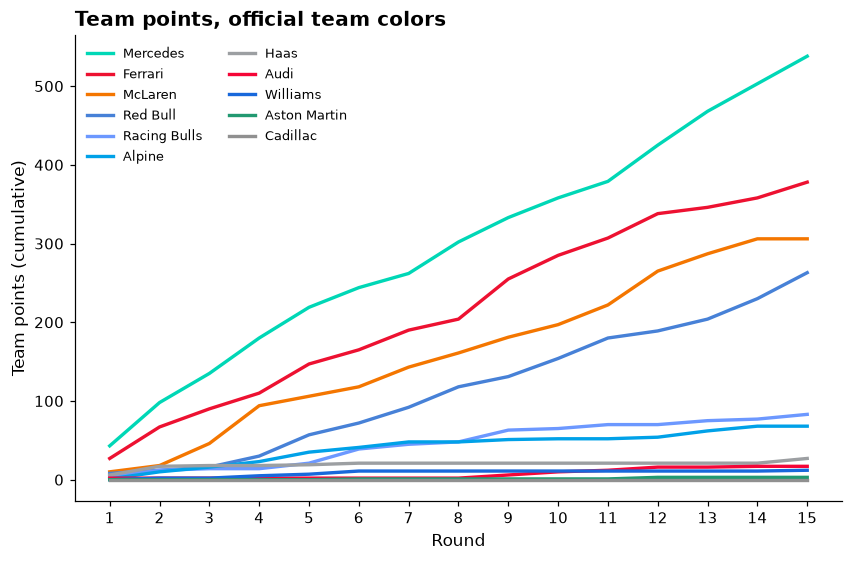

In [2]:
order = (ts[ts["round"] == LAST]
         .sort_values("points", ascending=False)["team"])
wide = ts.pivot(index="round", columns="team", values="points")

fig, ax = plt.subplots(figsize=(9, 5.5))
for team in order:
    ax.plot(wide.index, wide[team], color=OFFICIAL[team],
            lw=2.2, label=team)
ax.set(xlabel="Round", ylabel="Team points (cumulative)",
       title="Team points, official team colors")
ax.set_xticks(range(1, LAST + 1))
ax.legend(ncol=2, fontsize=8.5, frameon=False, loc="upper left")
save(fig, "fig01_official_colors")
plt.show()

**Result:** Mercedes is clearly on top, but try matching the bottom
lines to the legend. Four blues (Red Bull, Racing Bulls, Alpine,
Williams), two reds (Ferrari, Audi), two grays (Haas, Cadillac).

**Inference:** brand colors are picked for marketing, not to be
told apart. With 11 teams a legend lookup is slow and error prone.

### Do the official colors survive color blindness?

About 1 in 12 men has some red-green color blindness. We simulate
deuteranopia and protanopia (Machado et al. 2009) on the same 11
team colors.

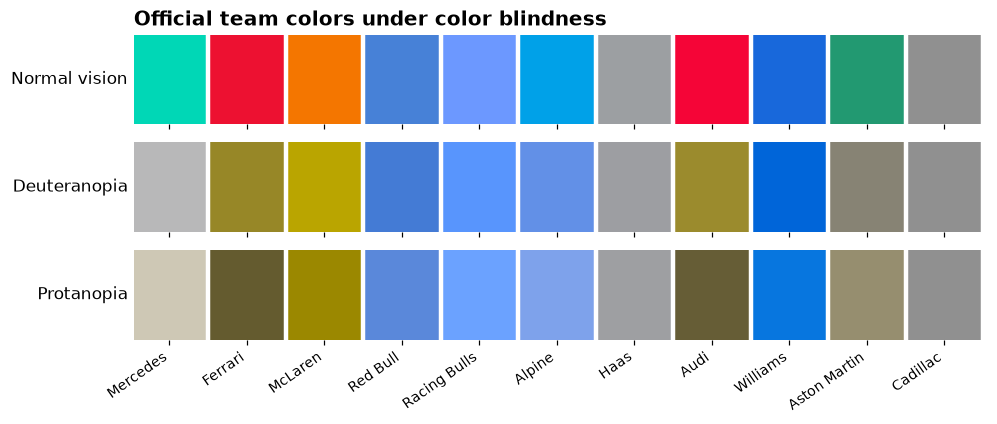

In [3]:
teams = list(order)
rows = [("Normal vision", lambda h: h),
        ("Deuteranopia", lambda h: simulate(h, "deuteranopia")),
        ("Protanopia", lambda h: simulate(h, "protanopia"))]

fig, axes = plt.subplots(len(rows), 1, figsize=(10, 3.6))
for ax, (label, f) in zip(axes, rows):
    for i, t in enumerate(teams):
        ax.add_patch(plt.Rectangle((i, 0), 0.92, 1,
                                   color=f(OFFICIAL[t])))
    ax.set_xlim(0, len(teams))
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_ylabel(label, rotation=0, ha="right", va="center")
    ax.set_xticks([i + 0.46 for i in range(len(teams))])
    ax.set_xticklabels(teams if ax is axes[-1] else [],
                       rotation=35, ha="right", fontsize=9)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].set_title("Official team colors under color blindness")
save(fig, "fig02_colorblind_check")
plt.show()

**Result:** under deuteranopia Ferrari and Audi turn into the same
olive, Mercedes turns gray and blends into Haas and Cadillac, and
the four blues are still four blues.

**Inference:** for a colorblind viewer the official palette has
maybe 5 usable colors for 11 teams. That is the problem Okabe-Ito
was designed for.

### The fix: fewer colors, a safe palette, direct labels

Okabe-Ito (the lecture's default qualitative scale) has 8 colors,
and 11 teams is too many for any qualitative scale anyway. So we
color only the four teams fighting at the front, gray the rest,
and label lines directly instead of using a legend.

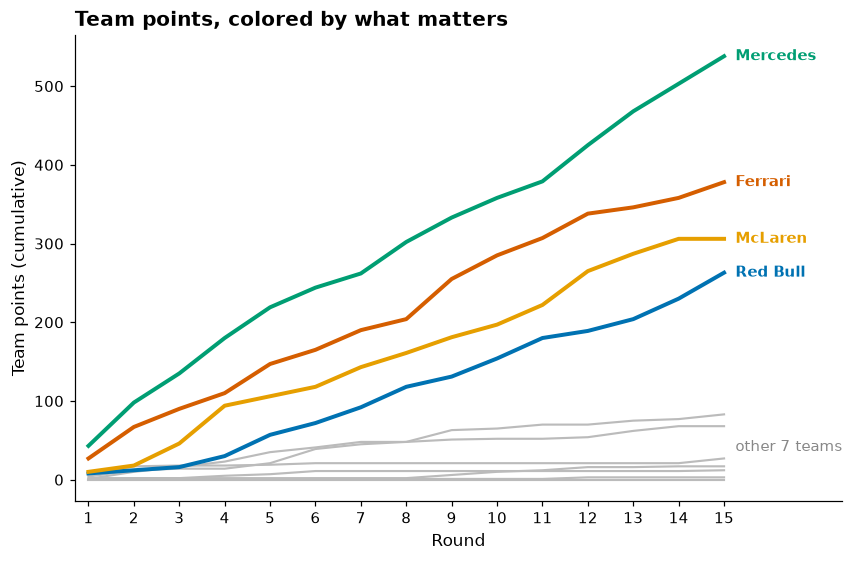

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for team in order[::-1]:
    top = team in TOP4
    ax.plot(wide.index, wide[team], lw=2.6 if top else 1.4,
            color=TOP4.get(team, GRAY), zorder=3 if top else 2)
    if top:
        ax.text(LAST + 0.25, wide[team].iloc[-1], team,
                color=TOP4[team], va="center", weight="bold")
rest = wide[[t for t in order if t not in TOP4]].iloc[-1]
ax.text(LAST + 0.25, rest.max() / 2, "other 7 teams",
        color="#888888", va="center")
ax.set(xlabel="Round", ylabel="Team points (cumulative)",
       title="Team points, colored by what matters")
ax.set_xticks(range(1, LAST + 1))
ax.set_xlim(0.7, LAST + 2.6)
save(fig, "fig03_fixed_colors")
plt.show()

**Result:** same data, same chart type. Now the story reads in one
glance: Mercedes pulls away, Ferrari and McLaren fight for second,
Red Bull is closing, and the other 7 teams are a separate league
(under 90 points each).

**Inference:** taking color *away* from 7 teams made the chart
better. Color is for the groups you want people to compare.

## 4.2 Color to represent values

### Sequential scale: finishing position, every driver, every race

22 drivers x 15 races = 330 results. A heatmap fits them all on one
screen; a line chart of 22 drivers would be spaghetti. Position is
ordered one way (P1 best), so it needs a **sequential** scale.

Left panel: the rainbow (jet) scale many tools default to.
Right panel: a single-hue sequential scale (dark = better).
Races a driver entered but did not finish get a gray x, like the
missing county in the lecture's Texas income map. Blank = not
entered (Tsunoda only raced 3 rounds as a stand-in).

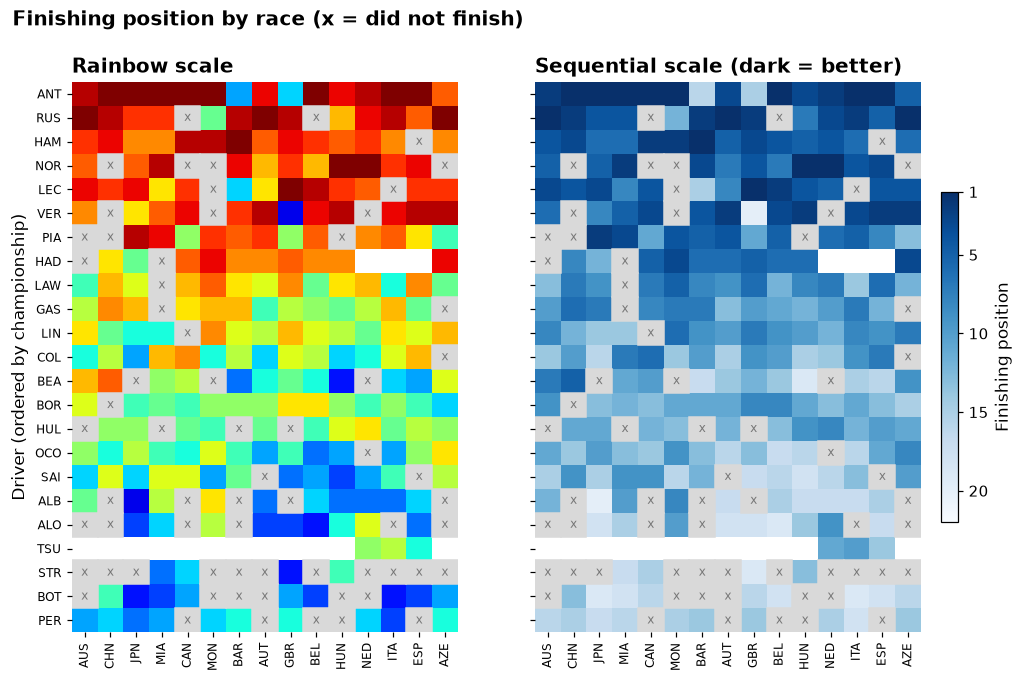

In [5]:
final = ds[ds["round"] == LAST].sort_values("position")
drivers = final["code"].tolist()
fin = (res.pivot(index="code", columns="round", values="finish")
          .reindex(drivers))

# entered but did not finish -> gray with an x
# not entered at all (e.g. Tsunoda's 12 missing races) -> blank
status = (res.pivot(index="code", columns="round", values="status")
             .reindex(drivers))
dnf = status.isin(["DNF", "DNS", "NC"])

def heat(ax, data, cmap, vmin, vmax, title):
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad("white")
    im = ax.imshow(np.ma.masked_invalid(data.values), cmap=cm,
                   vmin=vmin, vmax=vmax, aspect="auto")
    for (i, j) in zip(*np.where(dnf.values)):
        ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1,
                                   color="#D9D9D9"))
        ax.text(j, i, "x", ha="center", va="center",
                color="#777777", fontsize=8)
    ax.set_yticks(range(len(data)), data.index, fontsize=8)
    ax.set_xticks(range(data.shape[1]),
                  [ABBR[r - 1] for r in data.columns],
                  rotation=90, fontsize=8)
    ax.set_title(title)
    for s in ax.spines.values():
        s.set_visible(False)
    return im

fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), sharey=True)
heat(axes[0], fin, "jet_r", 1, 22, "Rainbow scale")
im = heat(axes[1], fin, "Blues_r", 1, 22,
          "Sequential scale (dark = better)")
cb = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.02)
cb.set_label("Finishing position")
cb.set_ticks([1, 5, 10, 15, 20])
cb.ax.invert_yaxis()
axes[0].set_ylabel("Driver (ordered by championship)")
fig.suptitle("Finishing position by race (x = did not finish)",
             x=0.08, ha="left", weight="bold", size=13)
save(fig, "fig04_sequential_heatmap")
plt.show()

**Result:** in the rainbow version your eye jumps to the yellow and
cyan bands, which are just the middle of the order (around P8 to
P14). They mean nothing special. The single-hue version reads
naturally: dark rows at the top (the front runners), fading down
the grid, and the gray x's pop out.

**Inference:** rainbow scales invent boundaries that are not in the
data. The sequential scale also exposes reliability: Stroll has 11
non-finishes in 15 races, Aston Martin 17 as a team.

### Diverging scale: places gained or lost

`gained` = grid position minus finishing position. This one has a
meaningful midpoint (0 = finished where you started), so it needs
a **diverging** scale: blue for places gained, red for places lost,
white for no change.

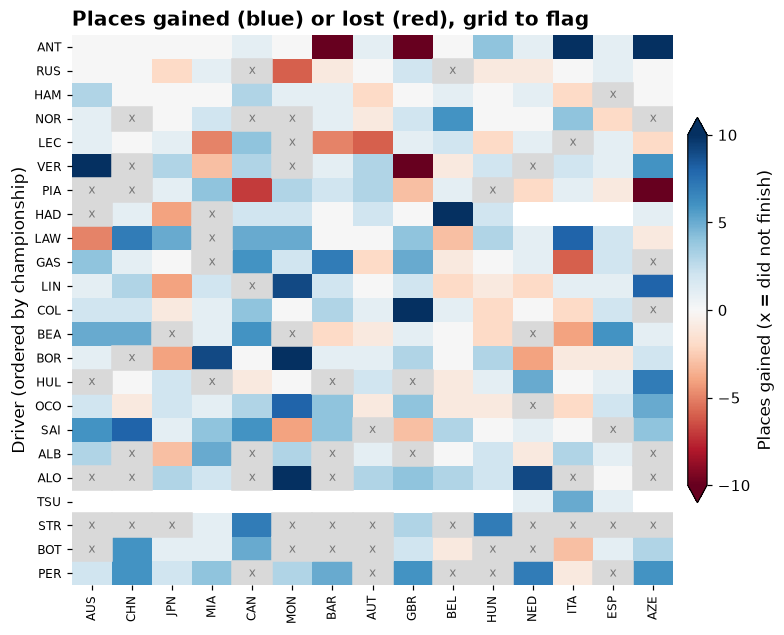

In [6]:
gain = (res.pivot(index="code", columns="round", values="gained")
           .reindex(drivers))
# a few +/-15 swings would wash out everything else, so the
# scale is capped at 10 places (arrows on the colorbar)
lim = 10

fig, ax = plt.subplots(figsize=(8.5, 6.5))
im = heat(ax, gain, "RdBu", -lim, lim,
          "Places gained (blue) or lost (red), grid to flag")
cb = fig.colorbar(im, ax=ax, shrink=0.7, pad=0.02,
                  extend="both")
cb.set_label("Places gained (x = did not finish)")
cb.set_ticks([-10, -5, 0, 5, 10])
ax.set_ylabel("Driver (ordered by championship)")
save(fig, "fig05_diverging_heatmap")
plt.show()

In [7]:
# who gains the most on average (finishers only)?
avg = (res.dropna(subset=["gained"]).groupby("code")["gained"]
          .agg(["mean", "count"]).round(1)
          .sort_values("mean", ascending=False))
pd.concat([avg.head(3), avg.tail(3)])

,mean,count
code,,
STR,4.5,4
ALO,4.1,9
PER,4.0,10
RUS,-0.5,13
LEC,-0.7,13
PIA,-0.7,12


**Result:** most cells are pale. Big blue cells are comeback drives
(Antonelli P19 to P1 at Italy, Hadjar P21 to P6 at Belgium). The
front runners are mostly white because you cannot gain places from
pole. Drivers at the back average the biggest gains (Stroll +4.5),
but mostly because cars ahead of them retire.

**Inference:** the diverging scale separates "moved forward" from
"went backwards" instantly, which a sequential scale could not do.
The midpoint (0) has to mean something for diverging to be right.

## 4.3 Color to highlight: the title fight

Everything gray except the story. The two Mercedes drivers lead
the championship, so their team color would make them identical.
We use two Okabe-Ito accents instead.

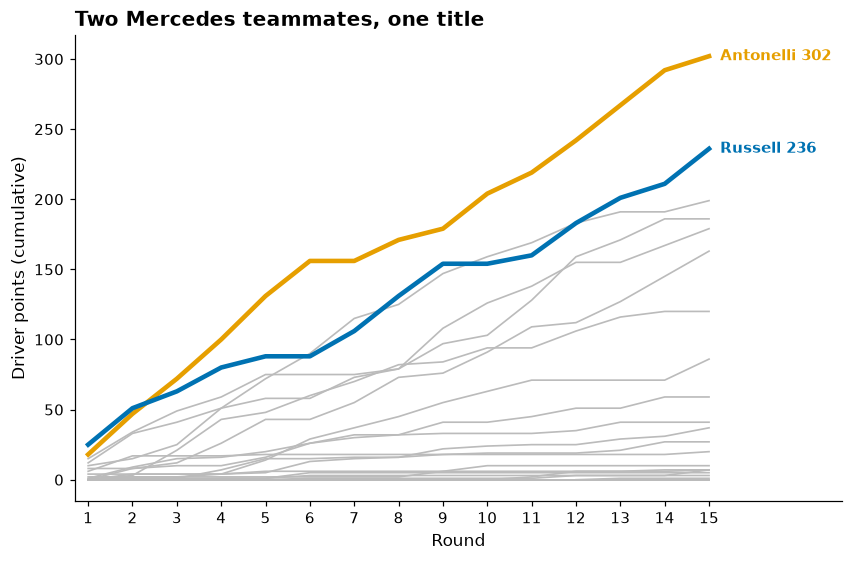

In [8]:
dw = ds.pivot(index="round", columns="code", values="points")
focus = {"ANT": OKABE_ITO["orange"], "RUS": OKABE_ITO["blue"]}
names = {"ANT": "Antonelli", "RUS": "Russell"}

fig, ax = plt.subplots(figsize=(9, 5.5))
for code in dw.columns:
    if code not in focus:
        ax.plot(dw.index, dw[code], color=GRAY, lw=1.1)
for code, c in focus.items():
    ax.plot(dw.index, dw[code], color=c, lw=3)
    ax.text(LAST + 0.25, dw[code].iloc[-1],
            f"{names[code]} {dw[code].iloc[-1]:.0f}",
            color=c, va="center", weight="bold")
ax.set(xlabel="Round", ylabel="Driver points (cumulative)",
       title="Two Mercedes teammates, one title")
ax.set_xticks(range(1, LAST + 1))
ax.set_xlim(0.7, LAST + 3)
save(fig, "fig06_highlight_title_fight")
plt.show()

In [9]:
lead = dw.idxmax(axis=1)
gap = (dw["ANT"] - dw["RUS"]).astype(int)
pd.DataFrame({"leader": lead, "ANT minus RUS": gap}).T

round,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
leader,RUS,RUS,ANT,ANT,ANT,ANT,ANT,ANT,ANT,ANT,ANT,ANT,ANT,ANT,ANT
ANT minus RUS,-7,-4,9,20,43,68,50,40,25,50,59,59,66,81,66


**Result:** Russell led after rounds 1 and 2, Antonelli has led
every round since and is 66 points clear. Everyone else is gray
context.

**Inference:** highlighting works because we chose the story first.
We also had to drop the team color here, since both drivers are
Mercedes and would look identical.

## Takeaways for Lecture 4

- **Distinguish (4.1):** a qualitative scale needs colors people
  can tell apart, including colorblind people. Official brand
  colors fail that test. Okabe-Ito, plus fewer colored groups, fixes
  it.
- **Represent values (4.2):** ordered data gets a sequential scale.
  Data with a meaningful middle gets a diverging scale. Rainbow
  scales add fake structure.
- **Highlight (4.3):** gray out the context, color the story, label
  directly.